# Customer Churn Prediction: who will leave, and who should we call?

**Business question.** A subscription business loses about 1 in 4 customers. The retention team can
only contact a limited number of customers each month. Which customers should they target, and is
the campaign worth running?

**What this notebook does**
1. Cleans the data and engineers business features
2. Explores what drives churn
3. Compares four models with cross-validation
4. Tunes the best model and evaluates it on a held-out test set
5. Picks the targeting threshold that **maximises campaign profit**, not accuracy
6. Explains predictions with SHAP so the business can act on them

Data: IBM Telco Customer Churn sample (7,043 customers, 21 columns).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from churn.business import lift_table, profit_curve
from churn.features import add_features, clean, load_raw, make_preprocessor, NUMERIC_FEATURES, CATEGORICAL_FEATURES

RANDOM_STATE = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:.3f}".format)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load and check the data

In [2]:
raw = load_raw(ROOT / "data" / "raw" / "telco_churn.csv")
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.65,Yes


In [3]:
# Data quality: TotalCharges is stored as text and has blanks
blank_total = pd.to_numeric(raw["TotalCharges"], errors="coerce").isna()
print("Blank TotalCharges:", blank_total.sum())
print("Tenure of those rows:", raw.loc[blank_total, "tenure"].unique())
print("Duplicate customer IDs:", raw["customerID"].duplicated().sum())

Blank TotalCharges: 11
Tenure of those rows: [0]
Duplicate customer IDs: 0


The 11 blank `TotalCharges` all belong to customers with `tenure = 0`: they joined but have not been
billed yet. Their total charges are 0. This is a domain fix, not mean imputation.

In [4]:
df = add_features(clean(raw))
print(f"Overall churn rate: {df['Churn'].mean():.1%}")

Overall churn rate: 26.5%


## 2. What drives churn?

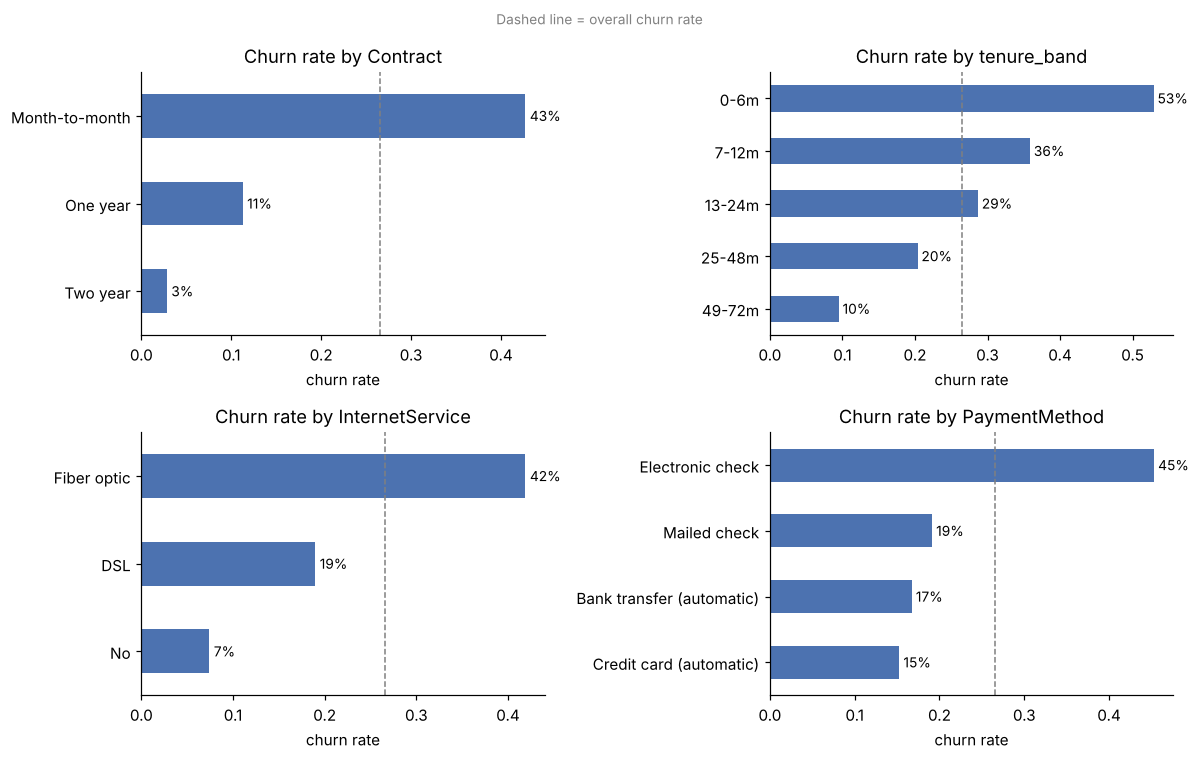

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, ["Contract", "tenure_band", "InternetService", "PaymentMethod"]):
    rate = df.groupby(col)["Churn"].mean().sort_values()
    rate.plot.barh(ax=ax, color="#4C72B0")
    ax.axvline(df["Churn"].mean(), color="grey", ls="--", lw=1)
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("churn rate")
    ax.set_ylabel("")
    for i, v in enumerate(rate):
        ax.text(v + 0.005, i, f"{v:.0%}", va="center", fontsize=9)
fig.suptitle("Dashed line = overall churn rate", fontsize=9, color="grey")
fig.tight_layout()
fig.savefig(FIG / "churn_drivers.png", bbox_inches="tight")
plt.show()

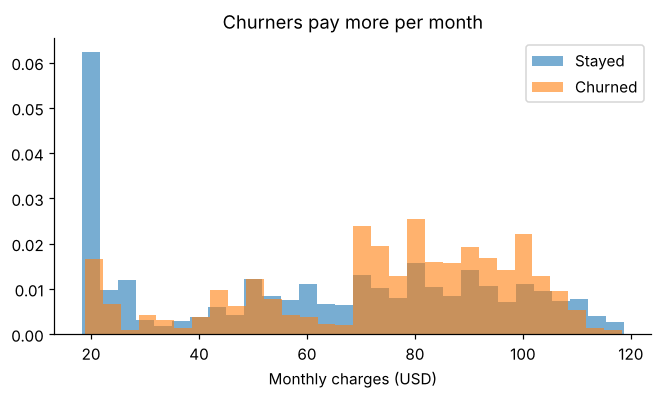

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for label, grp in df.groupby("Churn"):
    ax.hist(grp["MonthlyCharges"], bins=30, alpha=0.6, density=True,
            label="Churned" if label else "Stayed")
ax.set_xlabel("Monthly charges (USD)")
ax.set_title("Churners pay more per month")
ax.legend()
fig.savefig(FIG / "monthly_charges.png", bbox_inches="tight")
plt.show()

In [7]:
summary = pd.DataFrame({
    "segment": ["Month-to-month", "Two year", "Tenure 0-6m", "Tenure 49-72m", "Fiber optic", "Electronic check"],
    "churn_rate": [
        df.loc[df.Contract == "Month-to-month", "Churn"].mean(),
        df.loc[df.Contract == "Two year", "Churn"].mean(),
        df.loc[df.tenure_band == "0-6m", "Churn"].mean(),
        df.loc[df.tenure_band == "49-72m", "Churn"].mean(),
        df.loc[df.InternetService == "Fiber optic", "Churn"].mean(),
        df.loc[df.PaymentMethod == "Electronic check", "Churn"].mean(),
    ],
})
summary

,segment,churn_rate
0,Month-to-month,0.427
1,Two year,0.028
2,Tenure 0-6m,0.529
3,Tenure 49-72m,0.095
4,Fiber optic,0.419
5,Electronic check,0.453


**Findings**
- Contract type is the strongest single signal: month-to-month customers churn far more than two-year customers.
- Risk is concentrated in the first 6 months; long-tenure customers rarely leave.
- Fiber-optic and electronic-check customers churn more. Fiber customers also pay more, so price is a likely driver.

## 3. Model comparison (5-fold cross-validation on the training set)

I hold out 20% of customers as a final test set and never touch it until the end.
Because only 27% of customers churn, I track **PR-AUC** alongside ROC-AUC: it reflects how well
the model ranks the minority class, which is what the retention team uses.

In [8]:
X = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape)

(5634, 23) (1409, 23)


In [9]:
candidates = {
    "Baseline (always 'stay')": Pipeline([("prep", make_preprocessor()), ("model", DummyClassifier(strategy="prior"))]),
    "Logistic regression": Pipeline([("prep", make_preprocessor()), ("model", LogisticRegression(max_iter=2000, C=0.5))]),
    "Random forest": Pipeline([("prep", make_preprocessor(False)), ("model", RandomForestClassifier(
        n_estimators=400, min_samples_leaf=10, random_state=RANDOM_STATE, n_jobs=-1))]),
    "XGBoost": Pipeline([("prep", make_preprocessor(False)), ("model", XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4, eval_metric="logloss", random_state=RANDOM_STATE))]),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, pipe in candidates.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision"])
    rows.append({"model": name,
                 "ROC-AUC": s["test_roc_auc"].mean(), "ROC-AUC sd": s["test_roc_auc"].std(),
                 "PR-AUC": s["test_average_precision"].mean()})
cv_results = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False)
cv_results

,model,ROC-AUC,ROC-AUC sd,PR-AUC
2,Random forest,0.847,0.009,0.663
1,Logistic regression,0.847,0.011,0.662
3,XGBoost,0.844,0.008,0.658
0,Baseline (always 'stay'),0.500,0.000,0.265


Logistic regression is a strong, interpretable baseline on this dataset. I tune XGBoost to see if
a non-linear model adds value, and keep logistic regression as the benchmark to beat.

## 4. Tune XGBoost

In [10]:
search = RandomizedSearchCV(
    Pipeline([("prep", make_preprocessor(False)),
              ("model", XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE))]),
    param_distributions={
        "model__n_estimators": [200, 300, 500, 800],
        "model__learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1],
        "model__max_depth": [2, 3, 4, 5],
        "model__min_child_weight": [1, 3, 5, 10],
        "model__subsample": [0.7, 0.8, 1.0],
        "model__colsample_bytree": [0.6, 0.8, 1.0],
        "model__reg_lambda": [0.5, 1.0, 5.0],
    },
    n_iter=40, scoring="average_precision", cv=cv, random_state=RANDOM_STATE, n_jobs=-1,
)
search.fit(X_train, y_train)
print(f"Best CV PR-AUC: {search.best_score_:.3f}")
{k.replace("model__", ""): v for k, v in search.best_params_.items()}

Best CV PR-AUC: 0.670


{'subsample': 0.7,
 'reg_lambda': 5.0,
 'n_estimators': 500,
 'min_child_weight': 3,
 'max_depth': 2,
 'learning_rate': 0.02,
 'colsample_bytree': 1.0}

## 5. Final evaluation on the untouched test set

In [11]:
logreg = candidates["Logistic regression"].fit(X_train, y_train)
xgb = search.best_estimator_
models = {"Logistic regression": logreg, "XGBoost (tuned)": xgb}
test_scores = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}
pd.DataFrame({
    name: {"ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p)}
    for name, p in test_scores.items()
}).T

,ROC-AUC,PR-AUC
Logistic regression,0.845,0.651
XGBoost (tuned),0.847,0.666


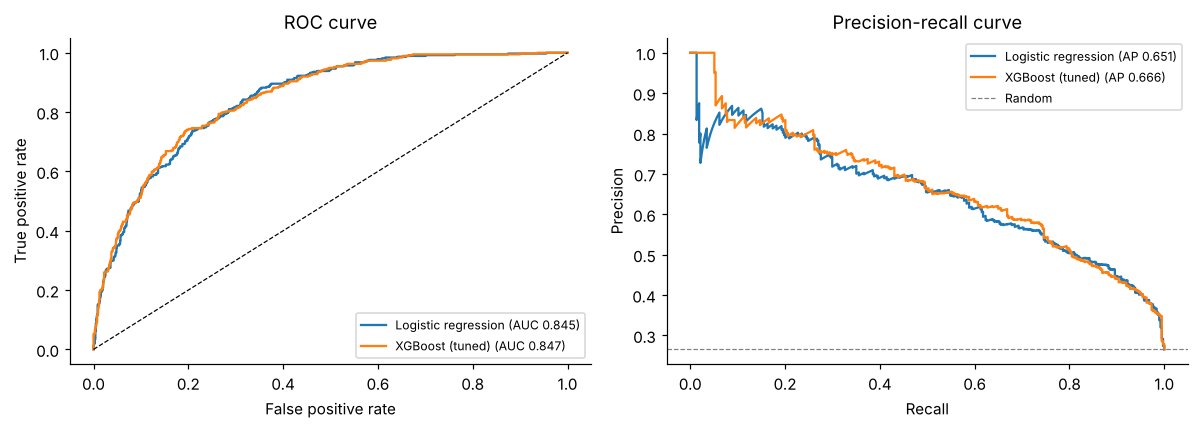

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, p in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    axes[1].plot(rec, prec, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_test.mean(), color="grey", ls="--", lw=0.8, label="Random")
axes[1].set(title="Precision-recall curve", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "roc_pr_curves.png", bbox_inches="tight")
plt.show()

Tuned XGBoost edges out logistic regression on the test set, but the gap is small. In production I
would weigh that small gain against logistic regression's simplicity and transparency. I continue with
whichever model scores higher on PR-AUC.

### How useful is the ranking? (lift table)

In [13]:
best_name = max(test_scores, key=lambda n: average_precision_score(y_test, test_scores[n]))
best_proba = test_scores[best_name]
print("Model used from here on:", best_name)
lift = lift_table(y_test, best_proba)
lift

Model used from here on: XGBoost (tuned)


,customers,churners,churn_rate,cum_share_of_churners,lift
decile,,,,,
1,141,106,0.752,0.283,2.832
2,141,81,0.574,0.500,2.164
3,141,64,0.454,0.671,1.710
4,141,41,0.291,0.781,1.095
5,141,33,0.234,0.869,0.882
6,140,25,0.179,0.936,0.673
7,141,14,0.099,0.973,0.374
8,141,8,0.057,0.995,0.214
9,141,0,0.000,0.995,0.000


In [14]:
top2 = lift["cum_share_of_churners"].iloc[1]
top3 = lift["cum_share_of_churners"].iloc[2]
print(f"Calling the riskiest 20% of customers reaches {top2:.0%} of all churners "
      f"({lift['lift'].iloc[0]:.1f}x lift in the top decile). Top 30% reaches {top3:.0%}.")

Calling the riskiest 20% of customers reaches 50% of all churners (2.8x lift in the top decile). Top 30% reaches 67%.


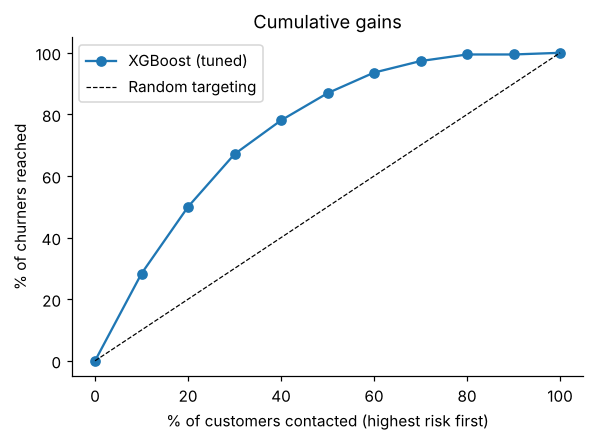

In [15]:
fig, ax = plt.subplots(figsize=(6, 4))
share = np.r_[0, lift["cum_share_of_churners"].values]
pct = np.linspace(0, 100, len(share))
ax.plot(pct, share * 100, marker="o", label=best_name)
ax.plot([0, 100], [0, 100], "k--", lw=0.8, label="Random targeting")
ax.set(xlabel="% of customers contacted (highest risk first)", ylabel="% of churners reached",
       title="Cumulative gains")
ax.legend()
fig.savefig(FIG / "cumulative_gains.png", bbox_inches="tight")
plt.show()

## 6. Choose the threshold that maximises profit

Accuracy and the default 0.5 cut-off ignore costs. I model a retention campaign
(assumptions in `src/churn/business.py`, easy to change):
- each contacted customer gets an offer costing **$50**
- **30%** of contacted churners are saved
- a saved customer is worth **12 months** of their monthly charge

To avoid tuning the threshold on the test set, I pick it with out-of-fold predictions on the
training set, then report the profit it gives on the test set.

In [16]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

best_model = models[best_name]
oof = cross_val_predict(clone(best_model), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
train_curve = profit_curve(y_train.values, oof, X_train["MonthlyCharges"].values)
best_t = float(train_curve.loc[train_curve["profit"].idxmax(), "threshold"])

test_curve = profit_curve(y_test.values, best_proba, X_test["MonthlyCharges"].values)
at = lambda t: test_curve.loc[np.isclose(test_curve["threshold"], t)].iloc[0]
target_all = (y_test.values * 0.30 * 12 * X_test["MonthlyCharges"].values).sum() - 50 * len(y_test)
comparison = pd.DataFrame([
    {"strategy": "Contact everyone", "customers_targeted": len(y_test),
     "churners_caught": int(y_test.sum()), "profit": target_all},
    {"strategy": "Model, default threshold 0.50", **at(0.50).drop("threshold").to_dict()},
    {"strategy": f"Model, profit-optimal threshold {best_t:.2f}", **at(best_t).drop("threshold").to_dict()},
])
comparison[["customers_targeted", "churners_caught"]] = comparison[["customers_targeted", "churners_caught"]].astype(int)
comparison["profit"] = comparison["profit"].round(0)
comparison

,strategy,customers_targeted,churners_caught,profit
0,Contact everyone,1409,374,27524.000
1,"Model, default threshold 0.50",288,190,38545.000
2,"Model, profit-optimal threshold 0.21",649,314,51516.000


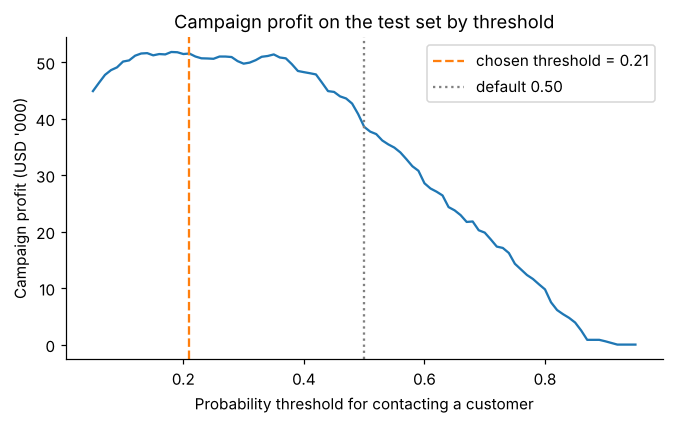

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(test_curve["threshold"], test_curve["profit"] / 1000)
ax.axvline(best_t, color="C1", ls="--", label=f"chosen threshold = {best_t:.2f}")
ax.axvline(0.5, color="grey", ls=":", label="default 0.50")
ax.set(xlabel="Probability threshold for contacting a customer", ylabel="Campaign profit (USD '000)",
       title="Campaign profit on the test set by threshold")
ax.legend()
fig.savefig(FIG / "profit_curve.png", bbox_inches="tight")
plt.show()

## 7. Why does the model flag a customer? (SHAP)

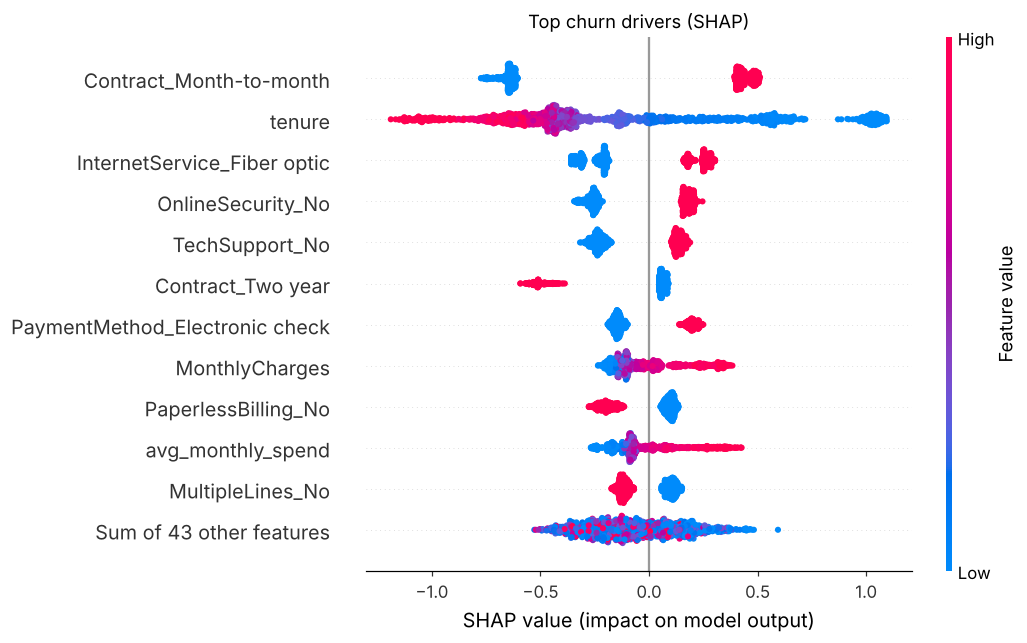

In [18]:
if best_name.startswith("XGBoost"):
    prep, clf = best_model.named_steps["prep"], best_model.named_steps["model"]
    Xt = pd.DataFrame(prep.transform(X_test), columns=prep.get_feature_names_out())
    explainer = shap.TreeExplainer(clf)
    sv = explainer(Xt)
else:
    prep, clf = best_model.named_steps["prep"], best_model.named_steps["model"]
    Xt = pd.DataFrame(prep.transform(X_test), columns=prep.get_feature_names_out())
    explainer = shap.LinearExplainer(clf, pd.DataFrame(prep.transform(X_train), columns=Xt.columns))
    sv = explainer(Xt)

shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("Top churn drivers (SHAP)")
plt.savefig(FIG / "shap_summary.png", bbox_inches="tight")
plt.show()

In [19]:
mean_abs = pd.Series(np.abs(sv.values).mean(axis=0), index=Xt.columns).sort_values(ascending=False)
mean_abs.head(10).rename("mean |SHAP|").to_frame()

,mean |SHAP|
Contract_Month-to-month,0.536
tenure,0.513
InternetService_Fiber optic,0.253
OnlineSecurity_No,0.222
TechSupport_No,0.186
Contract_Two year,0.170
PaymentMethod_Electronic check,0.165
MonthlyCharges,0.135
PaperlessBilling_No,0.134
avg_monthly_spend,0.127


## 8. Recommendations

1. **Target by risk, not by blanket campaign.** Ranking customers by predicted risk concentrates
   churners at the top of the list (see lift table), so a call list of the top 20-30% reaches most churners.
2. **Use the profit-optimal threshold.** It is set from campaign economics, not the arbitrary 0.5 cut-off.
3. **Fix the root causes the model surfaces:** move month-to-month customers to annual contracts
   (e.g. a discount for switching), give new customers a strong first-6-months onboarding, and review
   fiber-optic pricing.
4. **Next steps:** A/B test the retention offer to measure the real save rate (the 30% here is an
   assumption), then retrain monthly and monitor drift in contract mix and pricing.